# Weather Conditions Across the 2025 Formula 1 Season

**Authors:** Temirkhan Adilet and Bertayev Azat  
**Professor:** Koishiyeva

## Research question
How did air temperature, precipitation, relative humidity and wind differ between Formula 1 circuits **on the local race days of the 2025 season**?

This notebook combines a static-HTML Wikipedia scrape with Open-Meteo's Historical Weather API. The analysis contains 24 race days and 576 hourly rows. Each race contributes its local civil day, not its practice/qualifying days and not just the race-session hours. Las Vegas therefore uses **22 November 2025**, its Saturday local date.

**Data meaning:** ERA5 atmospheric reanalysis estimates near each circuit. These are not on-track measurements, track-surface temperatures, race-control observations or evidence about driver performance.

## 1. Reproducible setup

Run this notebook from the project folder after installing `requirements.txt`. By default, the notebook uses the included raw cache and makes **no network requests**. It verifies each cached file against its acquisition-time SHA-256 hash, reparses the HTML, re-cleans the JSON and regenerates all CSVs and charts.

To acquire missing sources deliberately, run `python src/build_data.py --online` before rerunning the notebook. That command checks Wikipedia's robots.txt, identifies the educational client, spaces requests by at least 1.2 seconds and stops on HTTP errors. It does not bypass access denial. Existing cached sources are kept for an exact reproducible snapshot.

In [1]:
from pathlib import Path
import os, sys, json
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    raise RuntimeError('Start this notebook in the extracted f1_weather_project folder')
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.jupyter' / 'matplotlib'))
os.environ.setdefault('XDG_CACHE_HOME', str(ROOT / '.jupyter' / 'cache'))
sys.path.insert(0, str(ROOT / 'src'))
import requests
from bs4 import BeautifulSoup
import numpy as np
import pandas as pd
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown, Image
from pipeline import parse_calendar, parse_coordinates, clean_weather, expected_hours, VARIABLES
from sources import SourceStore
from build_data import build_dataset
from analysis import analyze, create_figures, DAILY_VARS, LABELS, CODES, SHORT
pd.set_option('display.max_columns', 16)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')
print('Working folder:', ROOT.name)
print('pandas', pd.__version__, '| NumPy', np.__version__, '| Seaborn', sns.__version__)

No event loop hook running.
Working folder: f1_weather_project
pandas 2.2.3 | NumPy 2.3.5 | Seaborn 0.13.2


## 2. Sources, ethical collection and provenance

1. [Wikipedia: 2025 Formula One World Championship](https://en.wikipedia.org/wiki/2025_Formula_One_World_Championship): calendar table, race names, circuit links and dates
2. The corresponding 24 Wikipedia circuit pages: latitude and longitude from their geographic markup; exact article URLs are preserved in `calendar.csv`
3. [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api): hourly temperature at 2 m, relative humidity at 2 m, precipitation and wind speed at 10 m, with `models=era5`, `timezone=auto`, °C, %, mm and km/h

Raw HTML, the robots response, JSON payloads, request parameters, URLs, retrieval times and hashes are retained in `data/raw/`. Wikipedia text is credited to its contributors under [CC BY-SA](https://en.wikipedia.org/wiki/Wikipedia:Copyrights). Open-Meteo data are credited under [CC BY 4.0](https://open-meteo.com/en/licence); underlying ERA5 is from ECMWF/Copernicus. See the README for full reuse notes.

In [2]:
store = SourceStore(ROOT / 'data/raw', offline=True)
manifest = pd.DataFrame.from_dict(store.manifest, orient='index').rename_axis('cache_file')
for filename in store.manifest:
    store.read(filename)  # raises on a changed or undocumented raw file
print(f'Verified {len(manifest)} raw source files')
display(manifest[['kind','retrieved_at_utc','bytes','url']].head(6))
print('First retrieval:', manifest.retrieved_at_utc.min())
print('Last retrieval: ', manifest.retrieved_at_utc.max())

Verified 50 raw source files
First retrieval: 2026-10-07T09:47:03.072948+00:00
Last retrieval:  2026-10-07T09:50:00.104885+00:00


,kind,retrieved_at_utc,bytes,url
cache_file,,,,
wikipedia_robots.txt,robots,2026-10-07T09:47:03.072948+00:00,28275,https://en.wikipedia.org/robots.txt
calendar_2025.html,wikipedia_html,2026-10-07T09:47:04.570605+00:00,1559168,https://en.wikipedia.org/wiki/2025_Formula_One...
circuit_01.html,wikipedia_html,2026-10-07T09:48:01.310863+00:00,404198,https://en.wikipedia.org/wiki/Albert_Park_Circuit
circuit_02.html,wikipedia_html,2026-10-07T09:48:02.661568+00:00,476460,https://en.wikipedia.org/wiki/Shanghai_Interna...
circuit_03.html,wikipedia_html,2026-10-07T09:48:04.033417+00:00,708253,https://en.wikipedia.org/wiki/Suzuka_Circuit
circuit_04.html,wikipedia_html,2026-10-07T09:48:05.421968+00:00,477763,https://en.wikipedia.org/wiki/Bahrain_Internat...


### Static-HTML scraping approach

BeautifulSoup locates the calendar using its column headings rather than a fragile table number. It removes citation markers and ignores country-flag image links before selecting each circuit's textual article link. Coordinates are parsed from the `.geo` decimal field, with a degrees/minutes/seconds fallback. Missing coordinates, an incomplete calendar or an unexpected Las Vegas date trigger an error instead of guessed data.

The next cell exposes the actual scraper implementation. The full reusable functions are in `src/pipeline.py`.

In [3]:
import inspect
print(inspect.getsource(parse_calendar))
print(inspect.getsource(parse_coordinates))

def parse_calendar(html: str, expected_races: int | None = 24) -> pd.DataFrame:
    """Locate the calendar by its headers; extract names/links and local dates."""
    soup = BeautifulSoup(html, 'html.parser')
    for extra in soup.select('sup, .sortkey'):
        extra.decompose()
    records = []
    for table in soup.select('table'):
        first = table.find('tr')
        if first is None:
            continue
        headers = [_text(c).lower() for c in first.find_all(['th','td'], recursive=False)]
        if not all(any(term in h for h in headers) for term in ('round','grand prix','circuit','date')):
            continue
        indices = {term:next(i for i,h in enumerate(headers) if term in h) for term in ('round','grand prix','circuit','date')}
        for tr in table.find_all('tr')[1:]:
            cells=tr.find_all(['th','td'],recursive=False)
            if len(cells)<=max(indices.values()):
                continue
            number=re.fullmatch(r'\d+', _text(cells[indices

## 3. Define a race day correctly

The API returns UNIX instants; they are interpreted as UTC and converted to each returned IANA timezone. A race day runs from local midnight to the next local midnight. Expected coverage is calculated with timezone-aware boundaries, so a daylight-saving transition could produce 23 or 25 hours. The 24 selected 2025 dates each have 24 hours. The raw Las Vegas response contains a scalar UTC offset that differs from its historical race-date offset; the code deliberately uses the IANA timezone and UTC instants instead, recovering UTC−08:00 for 22 November.

**Precipitation requires a separate time alignment.** Open-Meteo labels precipitation by the end of its preceding one-hour accumulation. To measure rainfall over the actual civil race day, the row at hour *t* contains precipitation ending at *t + 1 hour*. Temperature, humidity and wind remain instantaneous values at *t*. The final 23:00 row therefore uses the precipitation endpoint at the following midnight.

The archive endpoint uses date-level bounds, so raw requests include the race date and the following date. Only the race-day instants plus that one necessary precipitation boundary contribute to the analysis. No next-day temperature, humidity or wind enters the final table. `precipitation_interval_end_utc` and `precipitation_interval_end_local` make this alignment auditable.

In [4]:
calendar, hourly, daily, quality = build_dataset(ROOT, offline=True)
display(calendar[['round','race_name','circuit','race_date','latitude','longitude']])
print(json.dumps(quality, indent=2))

01/24 Australian Grand Prix: 24 local-day hours
02/24 Chinese Grand Prix: 24 local-day hours
03/24 Japanese Grand Prix: 24 local-day hours
04/24 Bahrain Grand Prix: 24 local-day hours
05/24 Saudi Arabian Grand Prix: 24 local-day hours
06/24 Miami Grand Prix: 24 local-day hours
07/24 Emilia Romagna Grand Prix: 24 local-day hours
08/24 Monaco Grand Prix: 24 local-day hours
09/24 Spanish Grand Prix: 24 local-day hours
10/24 Canadian Grand Prix: 24 local-day hours
11/24 Austrian Grand Prix: 24 local-day hours
12/24 British Grand Prix: 24 local-day hours
13/24 Belgian Grand Prix: 24 local-day hours
14/24 Hungarian Grand Prix: 24 local-day hours
15/24 Dutch Grand Prix: 24 local-day hours
16/24 Italian Grand Prix: 24 local-day hours
17/24 Azerbaijan Grand Prix: 24 local-day hours
18/24 Singapore Grand Prix: 24 local-day hours
19/24 United States Grand Prix: 24 local-day hours
20/24 Mexico City Grand Prix: 24 local-day hours
21/24 São Paulo Grand Prix: 24 local-day hours
22/24 Las Vegas Grand 

,round,race_name,circuit,race_date,latitude,longitude
0,1,Australian Grand Prix,Albert Park Circuit,2025-03-16,-37.850,144.968
1,2,Chinese Grand Prix,Shanghai International Circuit,2025-03-23,31.339,121.220
2,3,Japanese Grand Prix,Suzuka Circuit,2025-04-06,34.842,136.539
3,4,Bahrain Grand Prix,Bahrain International Circuit,2025-04-13,26.032,50.511
4,5,Saudi Arabian Grand Prix,Jeddah Corniche Circuit,2025-04-20,21.632,39.104
5,6,Miami Grand Prix,Miami International Autodrome,2025-05-04,25.958,-80.239
6,7,Emilia Romagna Grand Prix,Imola Circuit,2025-05-18,44.341,11.713
7,8,Monaco Grand Prix,Circuit de Monaco,2025-05-25,43.735,7.421
8,9,Spanish Grand Prix,Circuit de Barcelona-Catalunya,2025-06-01,41.570,2.261
9,10,Canadian Grand Prix,Circuit Gilles Villeneuve,2025-06-15,45.501,-73.522


## 4. Cleaning and data-quality checks

- Names use snake_case and units appear in weather column names
- Dates, integer rounds/hours and numeric weather values are parsed explicitly
- Coordinates are scraped rather than manually invented; requested and returned grid coordinates remain separate
- The key `(round, timestamp_utc)` must be unique; duplicates fail loudly rather than being arbitrarily kept
- Missing or nonnumeric weather values are detected; **no imputation** and no replacement of unknown rain with zero
- Humidity must lie within 0–100%; precipitation and wind must be nonnegative; conservative physical bounds flag implausible temperatures/winds
- Every expected local race-day hour and each precipitation boundary must be present

These rules produced no missing weather values or duplicate hourly keys in this snapshot.

In [5]:
checks = pd.DataFrame({
    'check': ['Calendar races', 'Clean hourly rows', 'Expected hourly rows', 'Duplicate race/hour keys',
              'Missing weather cells', 'Imputed weather cells', 'Rows outside local race date'],
    'value': [len(calendar), len(hourly), quality['expected_hourly_rows'],
              hourly.duplicated(['round','timestamp_utc']).sum(),
              hourly[list(VARIABLES.values())].isna().sum().sum(), 0,
              (hourly.local_date != hourly.race_date).sum()]
})
display(checks)
assert len(calendar) == len(daily) == 24
assert len(hourly) == quality['expected_hourly_rows'] == 576
assert not hourly.duplicated(['round','timestamp_utc']).any()
assert hourly[list(VARIABLES.values())].notna().all().all()
assert (hourly.local_date == hourly.race_date).all()
assert hourly[hourly.race_name.str.contains('Las Vegas')].timestamp_local.str.endswith('-08:00').all()
print('DST control examples:', len(expected_hours('2025-03-09','America/New_York')),
      'hours in spring;', len(expected_hours('2025-11-02','America/New_York')), 'hours in autumn')
vegas = hourly[hourly.race_name.str.contains('Las Vegas')]
display(vegas[['race_date','timestamp_local','timestamp_utc','precipitation_interval_end_local']].iloc[[0,-1]])

DST control examples: 23 hours in spring; 25 hours in autumn


,check,value
0,Calendar races,24
1,Clean hourly rows,576
2,Expected hourly rows,576
3,Duplicate race/hour keys,0
4,Missing weather cells,0
5,Imputed weather cells,0
6,Rows outside local race date,0


,race_date,timestamp_local,timestamp_utc,precipitation_interval_end_local
504,2025-11-22,2025-11-22T00:00:00-08:00,2025-11-22 08:00:00+00:00,2025-11-22T01:00:00-08:00
527,2025-11-22,2025-11-22T23:00:00-08:00,2025-11-23 07:00:00+00:00,2025-11-23T00:00:00-08:00


In [6]:
display(hourly[['round','race_name','timestamp_local','temperature_c','relative_humidity_pct',
                'precipitation_mm','wind_speed_kmh','latitude','longitude','grid_latitude','grid_longitude']].head())
display(hourly[['round','hour_local','temperature_c','relative_humidity_pct','precipitation_mm','wind_speed_kmh']].dtypes.to_frame('dtype'))
print('Grid coordinates can differ from circuit coordinates because ERA5 represents a surrounding grid cell.')

Grid coordinates can differ from circuit coordinates because ERA5 represents a surrounding grid cell.


,round,race_name,timestamp_local,temperature_c,relative_humidity_pct,precipitation_mm,wind_speed_kmh,latitude,longitude,grid_latitude,grid_longitude
0,1,Australian Grand Prix,2025-03-16T00:00:00+11:00,25.300,53.000,0.000,21.200,-37.850,144.968,-37.750,145.000
1,1,Australian Grand Prix,2025-03-16T01:00:00+11:00,23.900,63.000,0.000,10.900,-37.850,144.968,-37.750,145.000
2,1,Australian Grand Prix,2025-03-16T02:00:00+11:00,22.600,72.000,0.000,6.600,-37.850,144.968,-37.750,145.000
3,1,Australian Grand Prix,2025-03-16T03:00:00+11:00,22.300,72.000,0.000,3.800,-37.850,144.968,-37.750,145.000
4,1,Australian Grand Prix,2025-03-16T04:00:00+11:00,22.000,74.000,0.000,5.300,-37.850,144.968,-37.750,145.000


,dtype
round,int64
hour_local,int64
temperature_c,float64
relative_humidity_pct,float64
precipitation_mm,float64
wind_speed_kmh,float64


## 5. Descriptive statistics and aggregation

Each race day contributes hourly means for temperature, humidity and wind; minimum and maximum temperature; total interval-aligned precipitation; the number of hours with positive precipitation; and maximum hourly wind. Wind is wind speed, not gust speed. A positive modeled precipitation amount does not prove that the race session was wet.

The primary comparison and correlations use **24 race-day rows**. The 576 hourly rows are repeated, temporally dependent samples and must not be treated as 576 independent race events.

In [7]:
descriptive, pearson, spearman, results = analyze(hourly, daily, ROOT)
display(daily[['round','race_name','temperature_mean_c','temperature_min_c','temperature_max_c',
               'relative_humidity_mean_pct','precipitation_total_mm','wet_hours','wind_speed_mean_kmh']])
display(descriptive.rename(index=LABELS))

,round,race_name,temperature_mean_c,temperature_min_c,temperature_max_c,relative_humidity_mean_pct,precipitation_total_mm,wet_hours,wind_speed_mean_kmh
0,1,Australian Grand Prix,18.642,12.000,25.300,76.750,13.700,18,16.963
1,2,Chinese Grand Prix,19.746,11.900,27.700,45.500,0.000,0,12.492
2,3,Japanese Grand Prix,13.737,11.100,18.200,79.458,18.600,17,9.433
3,4,Bahrain Grand Prix,24.896,24.700,25.200,71.458,0.000,0,28.742
4,5,Saudi Arabian Grand Prix,32.071,28.200,36.600,42.958,0.000,0,11.287
5,6,Miami Grand Prix,25.113,23.000,27.300,79.292,24.200,12,11.858
6,7,Emilia Romagna Grand Prix,18.338,13.500,23.200,59.792,0.000,0,14.346
7,8,Monaco Grand Prix,19.104,15.500,22.100,76.000,0.000,0,5.650
8,9,Spanish Grand Prix,21.921,18.500,25.700,77.292,0.000,0,8.725
9,10,Canadian Grand Prix,17.600,8.500,24.700,53.250,0.000,0,5.000


,count,mean,std,min,25%,50%,75%,max
Temperature mean (°C),24.000,20.457,4.432,13.737,17.551,19.425,23.604,32.071
Humidity mean (%),24.000,68.307,13.477,36.083,63.031,71.417,77.823,89.708
Precipitation total (mm),24.000,3.871,7.399,0.000,0.000,0.000,2.175,24.200
Wind mean (km/h),24.000,12.517,7.047,5.000,8.391,11.363,15.329,34.329


## 6. Visual comparisons

Figures use the same ERA5 model, variable heights, units and full-local-day scope. Three-letter race codes in the first two charts map to the calendar below.

Saved 5 labeled figures to figures/


Round,1,2,3,4,5,6,7,8,...,17,18,19,20,21,22,23,24
Code,AUS,CHN,JPN,BHR,SAU,MIA,EMR,MON,...,AZE,SGP,USA,MEX,SAO,LAS,QAT,ABU
Grand Prix,Australia,China,Japan,Bahrain,Saudi Arabia,Miami,Emilia Romagna,Monaco,...,Azerbaijan,Singapore,United States,Mexico City,São Paulo,Las Vegas,Qatar,Abu Dhabi


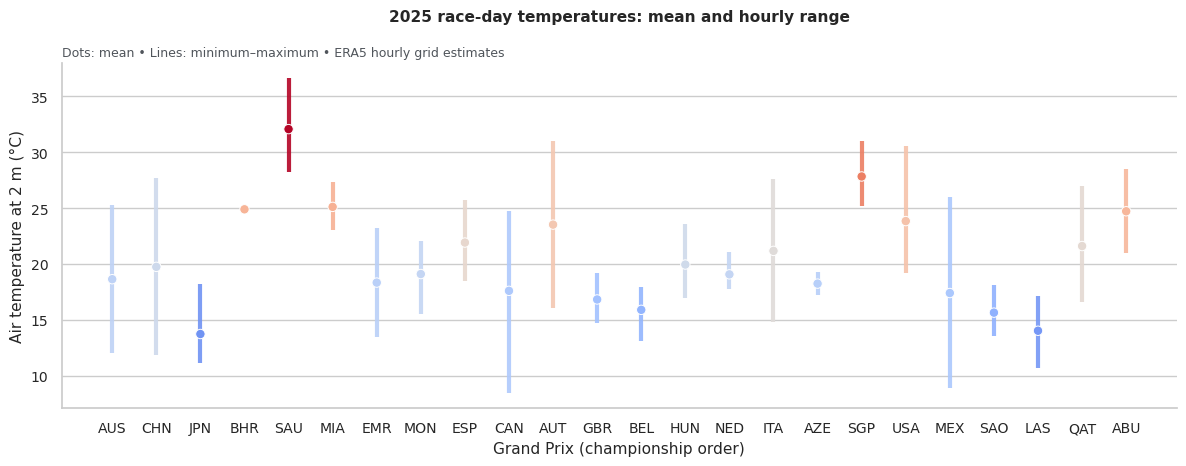

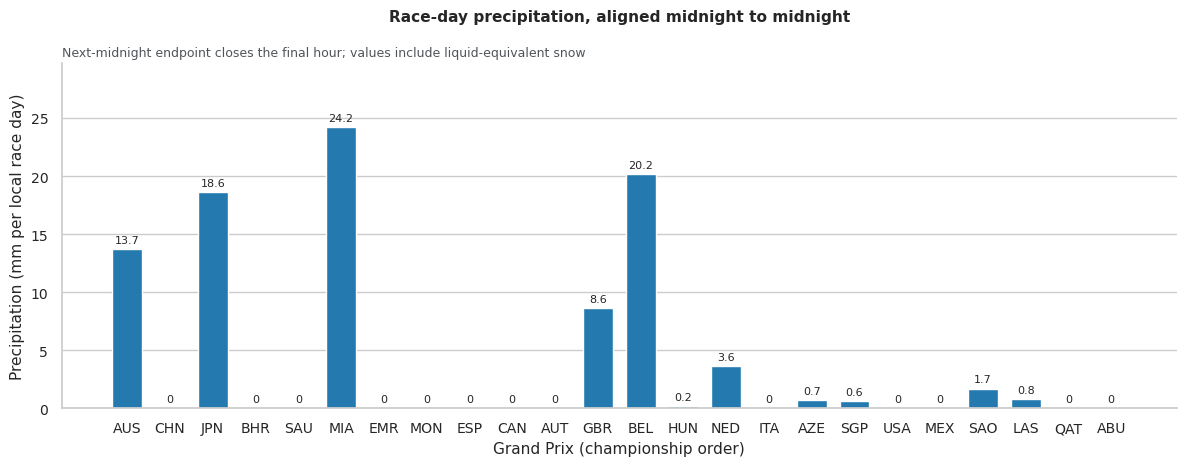

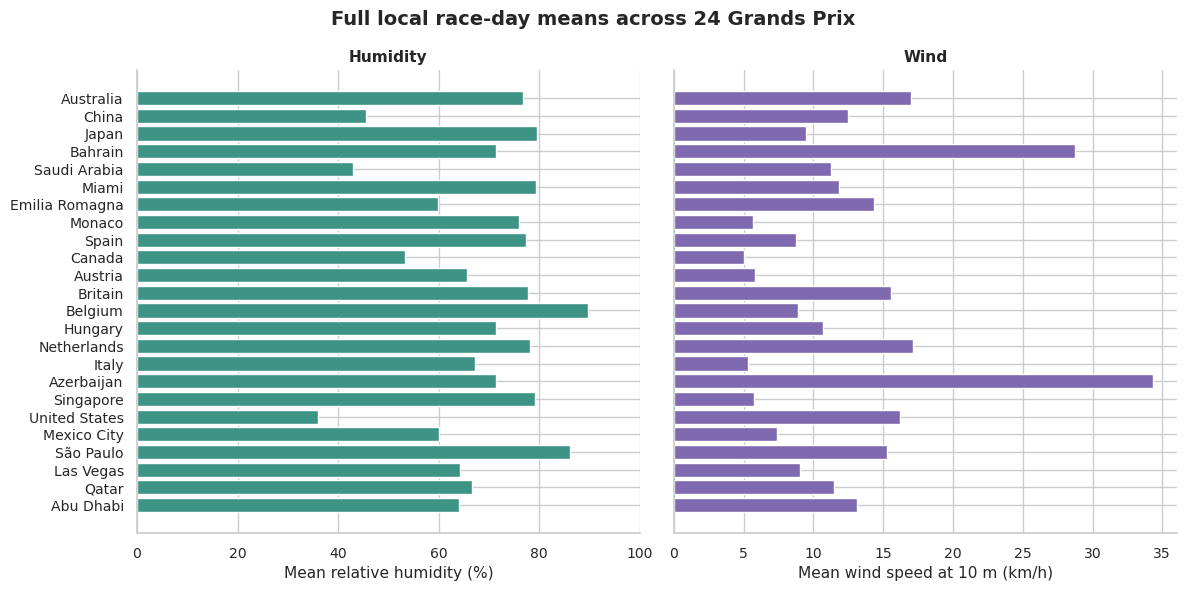

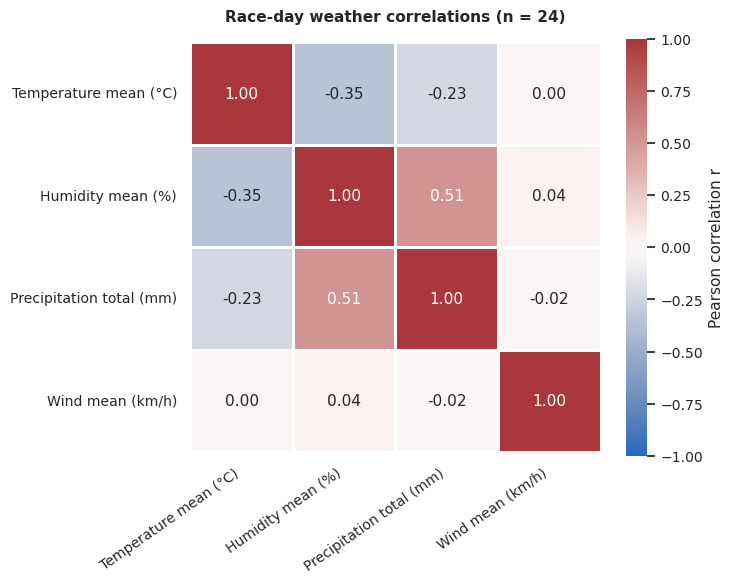

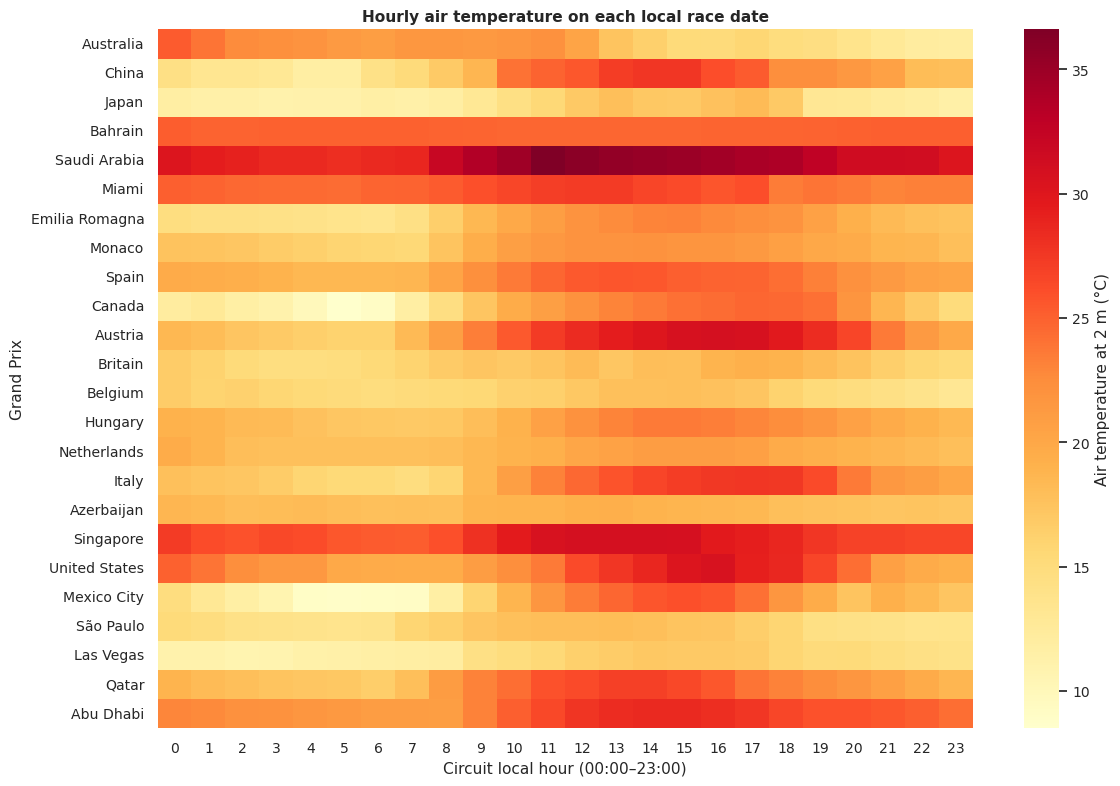

In [8]:
display(pd.DataFrame({'Round': range(1,25), 'Code': CODES, 'Grand Prix': SHORT}).set_index('Round').T)
figure_paths = create_figures(hourly, daily, ROOT, show=True)
print('Saved', len(figure_paths), 'labeled figures to figures/')

### Interpretation of the figures

The temperature ranges show both cross-location differences and within-day variation. Precipitation is uneven and many totals are zero, so a few wet dates can dominate simple summaries. Humidity and wind need separate scales because they have different units. The hourly heatmap shows why race-day averages cannot be read as race-session weather, especially for evening/night Grands Prix.

## 7. Associations, not causes

Pearson's correlation measures linear association among the 24 daily aggregates. Spearman's rank correlation is included because precipitation is skewed and contains many zeros. These coefficients describe this selected season only. They do not isolate weather effects from latitude, elevation, season, geography or each race's scheduling.

No p-values, causal claims or driver/team performance conclusions are made. A supplemental pooled-hour correlation CSV is saved for transparency, but is **descriptive only** because adjacent hours from the same race are not independent.

In [9]:
display(pearson.rename(index=LABELS, columns=LABELS).round(3))
display(spearman.rename(index=LABELS, columns=LABELS).round(3))
print('Comparison units for these matrices:', len(daily), 'race-day aggregates')

Comparison units for these matrices: 24 race-day aggregates


,Temperature mean (°C),Humidity mean (%),Precipitation total (mm),Wind mean (km/h)
Temperature mean (°C),1.000,-0.354,-0.233,0.005
Humidity mean (%),-0.354,1.000,0.512,0.040
Precipitation total (mm),-0.233,0.512,1.000,-0.024
Wind mean (km/h),0.005,0.040,-0.024,1.000


,Temperature mean (°C),Humidity mean (%),Precipitation total (mm),Wind mean (km/h)
Temperature mean (°C),1.000,-0.249,-0.429,0.002
Humidity mean (%),-0.249,1.000,0.758,0.056
Precipitation total (mm),-0.429,0.758,1.000,0.269
Wind mean (km/h),0.002,0.056,0.269,1.000


## 8. Results summary

In [10]:
warm = results['warmest_day_mean']; cool = results['coolest_day_mean']
wet = results['wettest_day']; windy = results['windiest_day_mean']
r_th = pearson.loc['temperature_mean_c','relative_humidity_mean_pct']
r_hp = pearson.loc['relative_humidity_mean_pct','precipitation_total_mm']
text = f"""
- Warmest local race-day mean: **{warm['race_name']}**, **{warm['value']:.2f} °C**
- Coolest local race-day mean: **{cool['race_name']}**, **{cool['value']:.2f} °C**
- Largest full-day precipitation total: **{wet['race_name']}**, **{wet['value']:.1f} mm**
- Highest mean 10 m wind speed: **{windy['race_name']}**, **{windy['value']:.2f} km/h**
- **{results['days_with_any_precipitation']} of 24** race days have any positive modeled precipitation; **{results['days_with_at_least_1mm']}** reach at least 1 mm
- Race-level temperature–humidity Pearson correlation: **r = {r_th:.3f}**
- Race-level humidity–precipitation Pearson correlation: **r = {r_hp:.3f}**

These values characterize whole local days and ERA5 grid estimates, not race-session conditions.
"""
display(Markdown(text))


- Warmest local race-day mean: **Saudi Arabian Grand Prix**, **32.07 °C**
- Coolest local race-day mean: **Japanese Grand Prix**, **13.74 °C**
- Largest full-day precipitation total: **Miami Grand Prix**, **24.2 mm**
- Highest mean 10 m wind speed: **Azerbaijan Grand Prix**, **34.33 km/h**
- **11 of 24** race days have any positive modeled precipitation; **7** reach at least 1 mm
- Race-level temperature–humidity Pearson correlation: **r = -0.354**
- Race-level humidity–precipitation Pearson correlation: **r = 0.512**

These values characterize whole local days and ERA5 grid estimates, not race-session conditions.


## 9. Limitations and conclusion

**Spatial resolution.** ERA5 is an approximately 0.25° (about 25 km) atmospheric reanalysis. Open-Meteo selects a nearby land grid cell and applies elevation handling; results can miss circuit-scale showers, coastal effects and local wind. Latitude/longitude in the raw response are grid coordinates, not necessarily the requested circuit point.

**Temporal scope.** Entire local civil race days were intentionally selected. The conclusions do not describe only the Grand Prix's start/end window. Precipitation intervals are explicitly aligned to the day, but temperature/humidity/wind are hourly instants rather than continuous measurements.

**Selection and sample size.** This is one 24-race season. Circuit geography, latitude, elevation, time of year and scheduling are confounded. Cross-race associations are descriptive, and an hour-level sample-size claim would overstate independent information.

**Source uncertainty.** Wikipedia pages can change, APIs may revise historical data and reanalysis is modeled. The included raw snapshot, hashes and exact parameters preserve the evidence used here. Amounts are limited by API precision; a tiny positive precipitation estimate is not proof of rain during the race.

**Conclusion.** A static web source and a public API can be integrated into an auditable race-day weather dataset. The largest analytical risks are incorrect local dates, confusing modeled grid weather with on-track observations, and misaligning precipitation accumulation timestamps. The validation rules address the first and third; the interpretation acknowledges the second.

## 10. Reproduce and inspect the deliverables

- `data/processed/calendar.csv`: 24 scraped race/circuit/date/coordinate records
- `data/processed/f1_weather_hourly.csv`: 576 clean, merged race-day rows
- `data/processed/f1_weather_daily.csv`: 24 daily aggregates
- `data/processed/quality_report.json`: validation counts and scope
- `data/processed/results_summary.json`: machine-readable findings
- `data/raw/manifest.json`: URLs, acquisition times, parameters and SHA-256 hashes
- `figures/`: five chart PNGs
- `src/`: documented source parsing, HTTP cache, cleaning and analysis functions
- `tests/`: parser, boundary alignment, DST, missingness, range, duplicate and cache tests

Run `python -m pytest tests -q` for validation, and `python scripts/execute_notebook.py` for a fresh end-to-end offline execution of every notebook cell in IPython (the tested path). Use `--engine kernel` for a standard separate Jupyter kernel when available. The assignment requires a GitHub repository link for submission. The project is prepared locally; remote repository creation/publication remains pending the owners’ choice and approval.

### References
- Wikipedia contributors. [2025 Formula One World Championship](https://en.wikipedia.org/wiki/2025_Formula_One_World_Championship), and the 24 circuit articles listed in `calendar.csv`; snapshot retrieval times are recorded in the manifest
- Open-Meteo. [Historical Weather API documentation](https://open-meteo.com/en/docs/historical-weather-api) and [data licence](https://open-meteo.com/en/licence)
- ECMWF/Copernicus Climate Change Service. [ERA5 hourly data on single levels](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels)

Code can be inspected and adapted. Review and understand the notebook and follow the institution's rules on attribution and assisted work before submitting.